# PART 0 — نمایش ویژهٔ هوش مصنوعی

**بازیِ حیوانات.** ماشین فقط ۸ حیوان با برچسب می‌بیند؛ بعد خودش یک خط می‌کشد و به حیواناتی که هرگز ندیده جواب می‌دهد.


همهٔ چیزی که ماشین می‌بیند (فقط ۸ سطر):
           وزن  طول_گوش برچسب
پرشین      4.5        5  گربه
سیامی      3.0        7  گربه
گره‌فیلد   6.0        4  گربه
شارتز      5.0        6  گربه
بولداگ    22.0        9    سگ
آلمانی    32.0       12    سگ
گلدن      28.0       11    سگ
دابلمان   38.0       13    سگ 



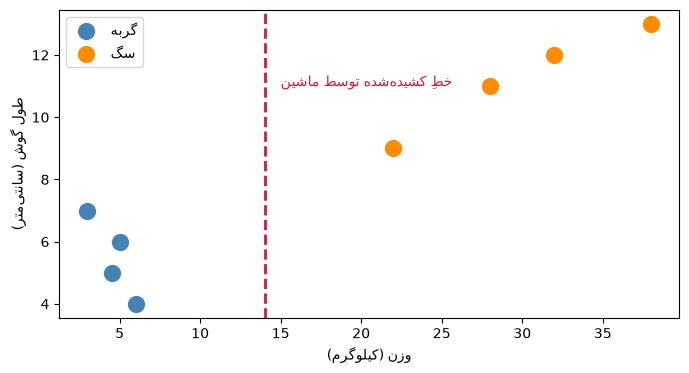

پاسخ ماشین به حیواناتی که هرگز ندیده بود:
  گرگ          ← سگ
  گربهٔ همسایه ← گربه
  توله‌سگ     ← گربه
  فیل          ← سگ


In [1]:
# دمو: بازیِ حیوانات — ماشین از ۸ مثال یک قانون یاد می‌گیرد
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import arabic_reshaper
from bidi.algorithm import get_display

def fa(text):
    # Persian text for matplotlib: shapes + orders it correctly
    return get_display(arabic_reshaper.reshape(str(text)))

# مرحلهٔ ۱: همهٔ چیزی که ماشین می‌بیند — ۸ حیوان، هر کدام دو عدد و یک برچسب
animals = pd.DataFrame({
    "وزن": [4.5, 3.0, 6.0, 5.0, 22, 32, 28, 38],      # کیلوگرم
    "طول_گوش": [5, 7, 4, 6, 9, 12, 11, 13],            # سانتی‌متر
    "برچسب": ["گربه", "گربه", "گربه", "گربه", "سگ", "سگ", "سگ", "سگ"],
}, index=["پرشین", "سیامی", "گره‌فیلد", "شارتز", "بولداگ", "آلمانی", "گلدن", "دابلمان"])
print("همهٔ چیزی که ماشین می‌بیند (فقط ۸ سطر):")
print(animals, "\n")

# مرحلهٔ ۲: یاد بگیر — ماشین خودش قانون را پیدا می‌کند
model = DecisionTreeClassifier(max_depth=1, random_state=42)
model.fit(animals[["وزن", "طول_گوش"]], animals["برچسب"])

# مرحلهٔ ۳: خطِ ماشین را ببین — هیچ انسانی این خط را نداد
plt.figure(figsize=(8, 4))
cats = animals[animals["برچسب"] == "گربه"]; dogs = animals[animals["برچسب"] == "سگ"]
plt.scatter(cats["وزن"], cats["طول_گوش"], c="steelblue", s=130, label="گربه")
plt.scatter(dogs["وزن"], dogs["طول_گوش"], c="darkorange", s=130, label="سگ")
plt.axvline(14, color="crimson", lw=2, ls="--")
plt.text(15, 11, fa("خطِ کشیده‌شده توسط ماشین"), color="crimson")
plt.xlabel(fa("وزن (کیلوگرم)")); plt.ylabel(fa("طول گوش (سانتی‌متر)")); plt.legend()
plt.show()

# مرحلهٔ ۴: امتحان! حیواناتی که ماشین هرگز ندیده است
new_animals = pd.DataFrame({
    "وزن": [35, 7, 2, 3000],
    "طول_گوش": [10, 5, 10, 20],
}, index=["گرگ", "گربهٔ همسایه", "توله‌سگ", "فیل"])
print("پاسخ ماشین به حیواناتی که هرگز ندیده بود:")
answers = model.predict(new_animals[["وزن", "طول_گوش"]])
for name, ans in zip(new_animals.index, answers):
    print(f"  {name:12} ← {ans}")

# جلسهٔ ۱ — یادگیری ماشین چیست؟
## روز اول — تو یک هوش مصنوعی می‌سازی

**هدف امروز تو:** *«تا پایان امروز، تو می‌توانی یک مدل یادگیری ماشین آموزش بدهی و به خانواده‌ات نشان بدهی.»*

**تحویل امشب:** یک مخزن گیت‌هاب با این نت‌بوک + مدلی که جواب می‌دهد: **«آیا من در تایتانیک زنده می‌ماندم؟»**

---

# PART A — جلسهٔ تدریس
*(این بخش را با هم در کلاس پر می‌کنیم)*


In [2]:
# COURSE SETUP — identical in every session. Just run it. (5 seconds)
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

import arabic_reshaper
from bidi.algorithm import get_display

def fa(text):
    # Persian text for matplotlib: shapes + orders it correctly
    return get_display(arabic_reshaper.reshape(str(text)))

plt.rcParams["figure.figsize"] = (8, 4)
print("Setup OK — let's build some AI.")


Setup OK — let's build some AI.


## A1 — بازی میوه: ویژگی‌ها و برچسب‌ها

هر نمونهٔ یادگیری ماشین با **ویژگی‌ها** (سرنخ‌ها) و یک **برچسب** (پاسخ) توصیف می‌شود.
سلول را اجرا کن و بازی کن: ستون پاسخ را بپوشان و فقط از سرنخ‌ها میوه را حدس بزن.


In [3]:
fruits = pd.DataFrame({
    "color":   ["red", "yellow", "purple", "yellow", "red", "green"],
    "size":    ["medium", "long", "small", "medium", "round", "medium"],
    "texture": ["smooth", "smooth", "wrinkly", "curved", "smooth", "smooth"],
    "fruit":   ["apple", "banana", "grape", "banana", "apple", "apple"],
})
fruits


,color,size,texture,fruit
0,red,medium,smooth,apple
1,yellow,long,smooth,banana
2,purple,small,wrinkly,grape
3,yellow,medium,curved,banana
4,red,round,smooth,apple
5,green,medium,smooth,apple


## A2 — کدام ویژگی مهم‌تر است؟

به جدول نگاه کن. **کدام سرنخ** برای حدس زدن میوه مفیدتر است: `color`، `size` یا `texture`؟

یک دقیقه بحث کن، بعد حدست را پایین بنویس. *(هنوز جواب غلطی وجود ندارد — جلسهٔ ۹ یاد می‌گیریم این را حساب کنیم!)*


In [4]:
most_useful_feature = "color"   # <-- change to your guess: "color", "size" or "texture"
print(f"I think '{most_useful_feature}' is the most useful clue.")


I think 'color' is the most useful clue.


## A3 — یادگیری نظارت‌شده: پنهان‌کردن پاسخ

یادگیری نظارت‌شده = یادگیری از نمونه‌هایی **که پاسخ دارند**.
مدل جدول کامل را درس می‌خواند... بعد **برچسب را پنهان می‌کنیم** و با نمونه‌های جدید ازش امتحان می‌گیریم.


In [5]:
study_table = fruits.copy()          # what the model studies WITH answers
quiz_table = fruits.drop(columns=["fruit"])  # what the model sees at quiz time

print("درس (ویژگی + برچسب):")
display(study_table.head(3))
print("امتحان (فقط ویژگی — برچسب پنهان است!):")
display(quiz_table.head(3))


درس (ویژگی + برچسب):


,color,size,texture,fruit
0,red,medium,smooth,apple
1,yellow,long,smooth,banana
2,purple,small,wrinkly,grape


امتحان (فقط ویژگی — برچسب پنهان است!):


,color,size,texture
0,red,medium,smooth
1,yellow,long,smooth
2,purple,small,wrinkly


## A4 — تایتانیک: ۸۹۱ مسافر، ۸۹۱ سطر

هر سطر یک زندگی است. هر ستون یک سرنخ. برچسب `survived` است (۱ = زنده ماند، ۰ = مرد).


In [6]:
titanic = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")\
           .rename(columns=str.lower)
titanic = titanic[["survived", "pclass", "sex", "age", "fare", "embarked"]].dropna()
print(f"{len(titanic)} passengers are ready to teach our model.")
titanic.head()


712 passengers are ready to teach our model.


,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


## A5 — داده به‌صورت عکس: چه کسی زنده ماند؟

*همیشه قبل از هر کاری، داده‌ات را ببین.*


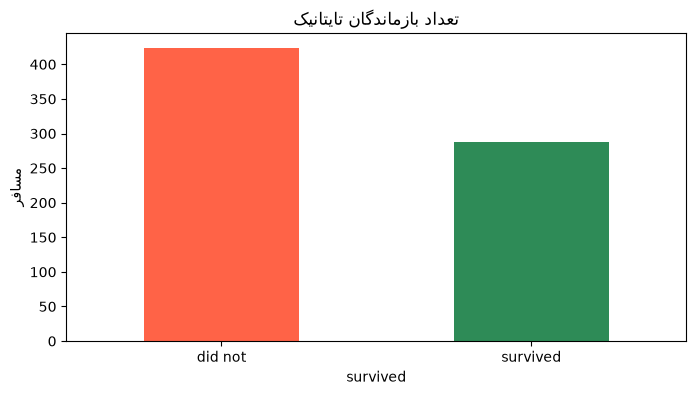

In [7]:
titanic["survived"].map({1: "survived", 0: "did not"}).value_counts().plot(
    kind="bar", color=["tomato", "seagreen"], rot=0)
plt.title(fa("تعداد بازماندگان تایتانیک")); plt.ylabel(fa("مسافر"))
plt.show()


## A6 — دو نمودار ضربهٔ نهایی


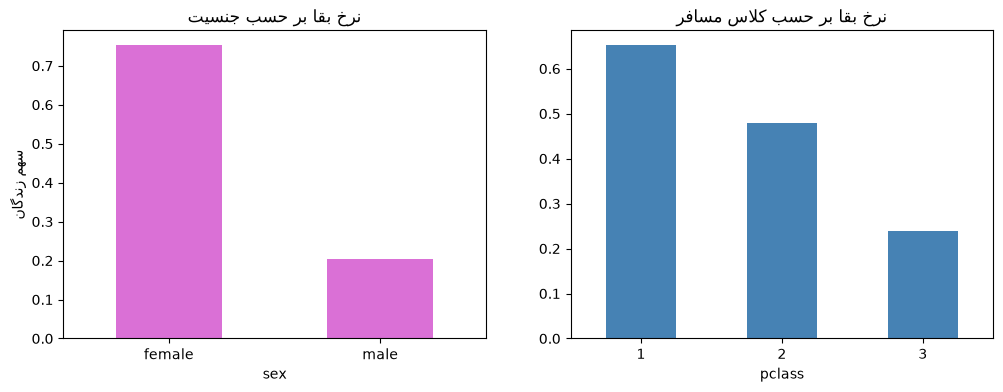

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
titanic.groupby("sex")["survived"].mean().plot(kind="bar", ax=axes[0], color="orchid", rot=0)
axes[0].set_title(fa("نرخ بقا بر حسب جنسیت")); axes[0].set_ylabel(fa("سهم زندگان"))
titanic.groupby("pclass")["survived"].mean().plot(kind="bar", ax=axes[1], color="steelblue", rot=0)
axes[1].set_title(fa("نرخ بقا بر حسب کلاس مسافر"))
plt.show()
# زنِ کلاس-۱ بودن در سال ۱۹۱۲ تقریباً بلیتِ بقا بود.


## A7 تا A9 — لحظهٔ جادویی: ساخت هوش مصنوعی در ۳ خط

با من تایپ کن. سه خط. همین یک هوش مصنوعی کامل است.


In [9]:
# خط صفر (جادو نیست، فقط آماده‌سازی): سرنخ‌ها را به عددی که مدل می‌فهمد تبدیل کن
X = titanic[["pclass", "age", "fare"]].copy()
X["is_female"] = (titanic["sex"] == "female").astype(int)
y = titanic["survived"]
X.head(3)


,pclass,age,fare,is_female
0,3,22.0,7.2500,0
1,1,38.0,71.2833,1
2,3,26.0,7.9250,1


In [10]:
# A8 — سه خط جادویی. شمرده یک دو سه، همه بگویید: یاد بگیر!
model = DecisionTreeClassifier(max_depth=3, random_state=42)  # ۱. انتخاب دانش‌آموز
model.fit(X, y)                                               # ۲. درس خواندن
print(f"تمام. مدل همین الان {len(X)} زندگی را در کمتر از یک ثانیه خواند.")


تمام. مدل همین الان 712 زندگی را در کمتر از یک ثانیه خواند.


زنده نمی‌ماند


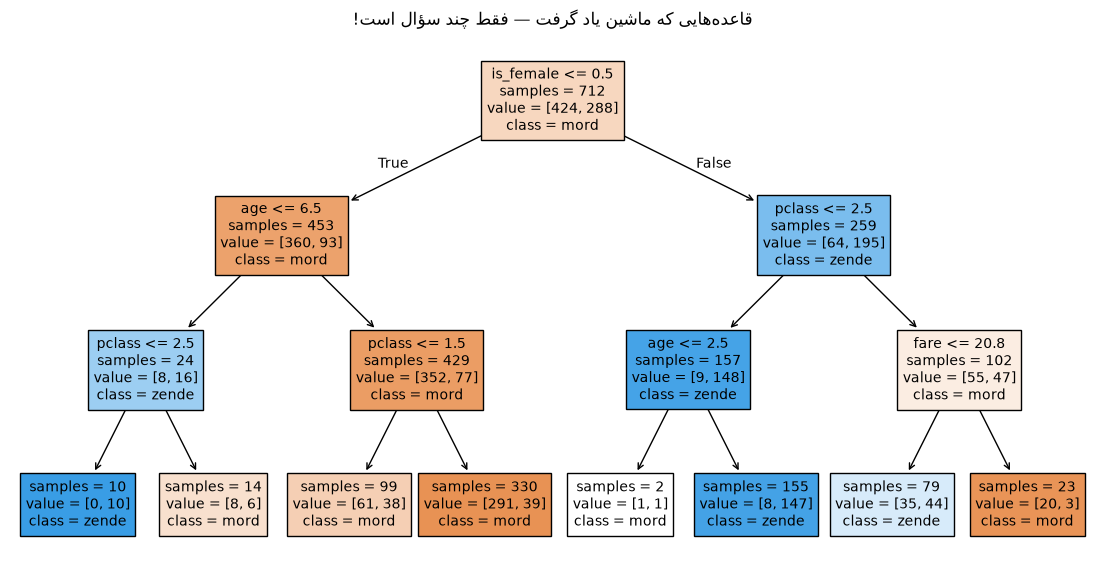

In [12]:
# A9 — ازش سؤال بپرس: آیا خودِ تو زنده می‌ماندی؟
me = pd.DataFrame([{"pclass": 2, "age": 13, "fare": 30, "is_female": 0}])  # <-- این را خودت کن!
verdict = model.predict(me)[0]
print("زنده می‌ماند" if verdict == 1 else "زنده نمی‌ماند")

# و نگاه کن — قاعده‌هایی که پیدا کرد فقط چند سؤال است. خودت هم می‌توانستی بکشی.
plt.figure(figsize=(14, 7))
plot_tree(model, feature_names=list(X.columns), class_names=["mord", "zende"],
          filled=True, fontsize=10, impurity=False)
plt.title(fa("قاعده‌هایی که ماشین یاد گرفت — فقط چند سؤال است!"))
plt.show()


---

# PART B — تمرین‌های خانه
**مهلت: قبل از جلسهٔ حل مسئله.** پاسخ‌ها را همین‌جا در همین سلول‌ها بنویس.
هر وقت خواستی خودت را نمره بده: `python judge/run.py s01_notebook.ipynb`

**چه چیزی باید یاد بگیری:** این تمرین‌ها مطمئن می‌شوند که خودت، تنها، می‌توانی دیتاست بسازی،
مدل آموزش بدهی و پیش‌بینی کنی.


## تمرین B1 — کارآگاه ویژگی‌ها (۱ نمره)

یک دوست می‌خواهد **قبولی یک دانش‌آموز در آزمون** را پیش‌بینی کند و این ویژگی‌ها را پیشنهاد می‌دهد:

`["name", "hours_studied", "favorite_color", "previous_score", "shoe_size"]`

فقط ویژگی‌هایی را که واقعاً می‌توانند به پیش‌بینی قبولی کمک کنند، به‌صورت یک **لیست** پایتونی بنویس.
(راهنما: آیا مدل از اسمِ کسی چیزی مفید یاد می‌گیرد؟)


In [ ]:
B1_good_features = ["hours_studied", "previous_score"]  # <-- پاسخ تو (لیستی از رشته‌ها)


## تمرین B2 — دیتاست خودت را بساز (۱ نمره)

حالا تو معلمی. یک دیتاست کوچک (یک DataFrame پانداسی) از **حداقل ۴ حیوان** بساز
با ویژگی‌های `["size", "can_fly"]` و برچسب `"animal"`. شرایط:

- دقیقاً همین ۳ ستون،
- حداقل ۴ سطر، هر کدام یک حیوان متفاوت،
- `size` یکی از `"small"`، `"medium"`، `"large"` باشد و `can_fly` عدد `0` یا `1`.


In [ ]:
B2_animals = pd.DataFrame({
    "size":     ["small", "large", "medium", "small"],
    "can_fly":  [0, 0, 0, 1],
    "animal":   ["cat", "elephant", "dog", "sparrow"],
})
# ^^^ با حیواناتِ خودت جایگزین کن. اسم ستون‌ها دقیقاً همین بماند: size, can_fly, animal


## تمرین B3 — سه خط جادویی (۱ نمره)

برای آموزش یک درخت تصمیم روی دیتاست حیواناتِ خودت، جاهای خالی را کامل کن.


In [ ]:
B2_animals_num = B2_animals.copy()
B2_animals_num["size_num"] = B2_animals_num["size"].map({"small": 0, "medium": 1, "large": 2})

B3_X = B2_animals_num[["size_num", "can_fly"]]     # ویژگی‌ها
B3_y = B2_animals_num["animal"]                    # برچسب

B3_model = DecisionTreeClassifier(random_state=42)  # ۱. انتخاب دانش‌آموز
B3_model.fit(B3_X, B3_y)                            # ۲. درس خواندن
B3_prediction = B3_model.predict(pd.DataFrame([{"size_num": 1, "can_fly": 0}]))[0]  # اندازه=متوسط، پرواز=۰ ← ؟
print("مدل می‌گوید حیوان متوسطِ بی‌پرواز این است:", B3_prediction)


## تمرین B4 — پیش‌بینی‌گر بقا (۱ نمره)

مدل تایتانیکِ خودت را آموزش بده (مثل کلاس، با `max_depth=3` و `random_state=42`)
و بقا را برای این مسافر پیش‌بینی کن: **کلاس ۳، پسر ۱۲ ساله، کرایهٔ ۷.۵.**

بعد جواب بده: او زنده ماند؟ عدد `1` (زنده ماند) یا `0` (نماند) را در `B4_answer` بگذار.


In [ ]:
# داده از قبل بارگذاری شده (titanic). مثل سلول A7، دقیقاً X و y را بساز.
B4_X = X.copy()
B4_y = y.copy()

B4_model = DecisionTreeClassifier(max_depth=3, random_state=42)
B4_model.fit(B4_X, B4_y)

new_passenger = pd.DataFrame([{"pclass": 3, "age": 12, "fare": 7.5, "is_female": 0}])
B4_answer = int(B4_model.predict(new_passenger)[0])   # باید 1 یا 0 باشد
print("مدل می‌گوید:", "زنده می‌ماند" if B4_answer == 1 else "زنده نمی‌ماند")


---

# تحویل بده!

وقتی هر چهار تمرین از داوری سربلند بیرون آمد:
1. این نت‌بوک را ذخیره کن.
2. آن را در مخزن گیت‌هاب دوره‌ات commit کن (معلمت نشانت می‌دهد، یا راهنمای کلاس را ببین).
3. به خانواده‌ات نشان بده: *«امروز یک هوش مصنوعی ساختم.»* — چون واقعاً ساختی.


---

# PART C — جلسهٔ حل مسئله
*(اول تمرین‌های خانه را زنده حل می‌کنیم — بعد این‌ها را)*


## C1 — موتور خیال

**مسافرهای خودت را اختراع کن** (هر کلاس، سن، کرایه و جنسیتی که دوست داری) و ببین مدل چه می‌گوید.
می‌توانی مسافری پیدا کنی که مدل در او *اشتباه* کند؟ می‌توانی مدل را بشکنی؟


In [ ]:
my_passengers = pd.DataFrame([
    {"pclass": 1, "age": 40, "fare": 500, "is_female": 1},
    {"pclass": 3, "age": 30, "fare": 5,  "is_female": 0},
    # سطرهای خودت را اینجا اضافه کن!
])
preds = model.predict(my_passengers)
for i, p in enumerate(preds):
    print(f"مسافر {i+1}: {'زنده می‌ماند' if p else 'زنده نمی‌ماند'}")


## C2 — انسان را شکست بده

قبل از اجرای سلول بعدی، بقا هر یک از این ۵ مسافر را خودت حدس بزن.
۵ حدست را بنویس (مثلاً `"01100"`)، بعد اجرا کن. **می‌توانی از ماشین جلو بزنی؟**


In [ ]:
challenge = pd.DataFrame([
    {"pclass": 1, "age": 35, "fare": 80,  "is_female": 1},
    {"pclass": 2, "age": 29, "fare": 26,  "is_female": 0},
    {"pclass": 3, "age": 21, "fare": 7,   "is_female": 0},
    {"pclass": 1, "age": 60, "fare": 90,  "is_female": 0},
    {"pclass": 3, "age": 6,  "fare": 12,  "is_female": 1},
])
my_guesses = "00000"  # <-- ۵ حدس تو، یک کاراکتر برای هر مسافر، قبل از اجرای predict
machine = "".join(str(p) for p in model.predict(challenge))
print("تو:    ", my_guesses)
print("ماشین:", machine)
score = sum(a == b for a, b in zip(my_guesses, machine))
print(f"تو {score}/5 بار با ماشین هم‌نظر بودی.")


## C3 — بحث: دانشِ ماشین کجا زندگی می‌کند؟

دوباره به عکس درخت در سلول A9 نگاه کن. مدل هیچ‌وقت کتاب تاریخ نخوانده.
هیچ‌وقت از کوه یخ نشنیده. **«دانش» او از کجا آمده؟**

*(جوابت را به جمع‌بندی بیاور — این، بذرِ همهٔ کارهای جلسهٔ ۲ است.)*
